# Reto avanzado 3: estabilidad de clústeres (Jackknife clustering)

**Pregunta:** si quitamos un subconjunto aleatorio de clientes y reentrenamos, ¿salen los mismos segmentos?

**Método:**
1. Se generan **N = 20 submuestras**, cada una excluyendo al azar el **15 %** de los clientes.
2. En cada una se entrena K-Means con el **mismo k** del reto 3.
3. Los números de clúster son arbitrarios en cada ejecución, así que se **alinean** con los del modelo de referencia
   emparejando centroides con el algoritmo húngaro (distancia mínima).
4. Métricas:
   - **ARI** de cada ejecución frente a la referencia.
   - **% de coincidencia por cliente:** en cuántas de las ejecuciones en las que aparece mantiene su segmento de referencia.
   - **Jaccard por clúster** (Hennig, 2007): solapamiento entre el clúster de referencia y su pareja en cada ejecución.
     Umbrales habituales: > 0,85 muy estable · 0,75–0,85 estable · 0,6–0,75 patrón débil · < 0,6 inestable.
   - **Saltos:** entre qué segmentos se mueven los clientes inestables.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Especificaciones_proyecto.md").exists())
PROC = ROOT / "data" / "processed"
FIG = ROOT / "modelo" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
BLUE = CAT[0]
DIV = ["#e34948", "#f0efec", "#2a78d6"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def show_md(text):
    display(Markdown(text))

In [2]:
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X = pd.read_csv(PROC / "features_modelo.csv", dtype={"client_id": str}).set_index("client_id")
ref = pd.read_csv(PROC / "segmentos_kmeans.csv", dtype={"client_id": str}).set_index("client_id").cluster.reindex(X.index).to_numpy()
cent_ref = pd.read_csv(PROC / "centroides_kmeans.csv").set_index("cluster").to_numpy()
nombres_path = PROC / "nombres_segmentos.csv"
NOMBRES = (pd.read_csv(nombres_path).set_index("cluster").nombre.to_dict() if nombres_path.exists()
           else {c: f"clúster {c}" for c in range(len(cent_ref))})
K = len(cent_ref)
N_RUNS, FRAC_OUT = 20, 0.15
Xv = X.to_numpy()
n = len(Xv)
print(f"k = {K} · clientes = {n:,} · {N_RUNS} submuestras excluyendo el {FRAC_OUT:.0%}")

k = 7 · clientes = 172,623 · 20 submuestras excluyendo el 15%


## 1. Ejecuciones Jackknife

In [3]:
rng = np.random.default_rng(SEED)
asign = np.full((N_RUNS, n), -1, dtype=np.int8)  # -1 = cliente excluido en esa ejecución
filas = []
for r in range(N_RUNS):
    incl = np.sort(rng.choice(n, size=int(n * (1 - FRAC_OUT)), replace=False))
    km = KMeans(n_clusters=K, n_init=10, random_state=SEED + r).fit(Xv[incl])
    coste = ((km.cluster_centers_[:, None, :] - cent_ref[None, :, :]) ** 2).sum(-1)
    fila_run, col_ref = linear_sum_assignment(coste)
    mapa = dict(zip(fila_run, col_ref))
    lab = np.vectorize(mapa.get)(km.labels_)
    asign[r, incl] = lab
    jac = {}
    for c in range(K):
        a, b = ref[incl] == c, lab == c
        jac[c] = (a & b).sum() / (a | b).sum()
    filas.append({"ejecución": r + 1, "ARI": adjusted_rand_score(ref[incl], lab),
                  "% coincidencia": (ref[incl] == lab).mean() * 100,
                  "desplazamiento máx. centroide": np.sqrt(coste[fila_run, col_ref]).max(),
                  **{f"Jaccard {c}": v for c, v in jac.items()}})
runs = pd.DataFrame(filas).set_index("ejecución")
runs[["ARI", "% coincidencia", "desplazamiento máx. centroide"]].describe().loc[["mean", "std", "min", "max"]]

,ARI,% coincidencia,desplazamiento máx. centroide
mean,0.852,92.833,0.912
std,0.126,7.863,0.830
min,0.569,74.117,0.022
max,0.999,99.972,3.121


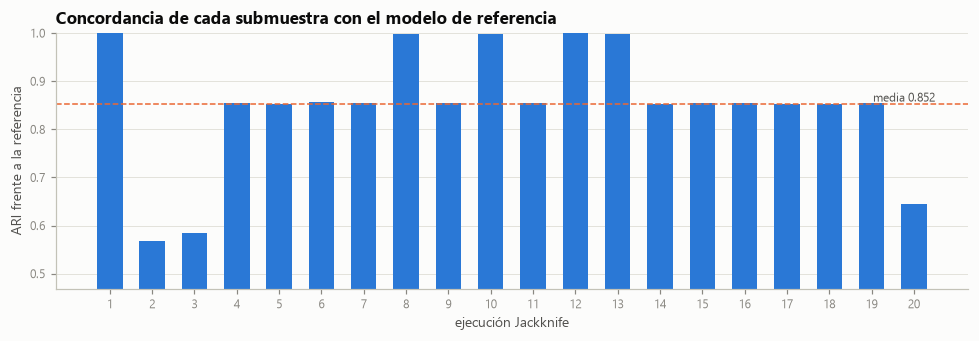

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(runs.index.astype(str), runs.ARI, width=0.6, color=BLUE)
ax.axhline(runs.ARI.mean(), color=CAT[1], lw=1, ls="--")
ax.text(len(runs) - 0.5, runs.ARI.mean(), f" media {runs.ARI.mean():.3f}", va="bottom", ha="right", fontsize=8, color=INK2)
ax.set_ylim(max(0, runs.ARI.min() - 0.1), 1.0); ax.grid(axis="x", visible=False)
ax.set_xlabel("ejecución Jackknife"); ax.set_ylabel("ARI frente a la referencia")
ax.set_title("Concordancia de cada submuestra con el modelo de referencia")
save(fig, "a3_ari_por_ejecucion.png")

## 2. Estabilidad de las asignaciones por cliente

Para cada cliente se cuenta en cuántas ejecuciones aparece (≈ 17 de 20) y en qué porcentaje de ellas conserva su segmento.

In [5]:
presente = asign >= 0
n_pres = presente.sum(0)
coinc = ((asign == ref[None, :]) & presente).sum(0) / np.maximum(n_pres, 1)
cli = pd.DataFrame({"cluster": ref, "apariciones": n_pres, "coincidencia": coinc}, index=X.index)
multi = cli[cli.apariciones >= 2]
resumen = pd.Series({
    "clientes en ≥ 2 submuestras": len(multi),
    "apariciones medias": multi.apariciones.mean(),
    "% coincidencia medio": multi.coincidencia.mean() * 100,
    "% clientes 100 % estables": (multi.coincidencia == 1).mean() * 100,
    "% clientes que saltan alguna vez": (multi.coincidencia < 1).mean() * 100,
    "% clientes inestables (< 80 % coincidencia)": (multi.coincidencia < 0.8).mean() * 100,
}, name="valor")
resumen.to_frame()

,valor
clientes en ≥ 2 submuestras,"172,623.000"
apariciones medias,17.000
% coincidencia medio,92.833
% clientes 100 % estables,54.251
% clientes que saltan alguna vez,45.749
% clientes inestables (< 80 % coincidencia),5.902


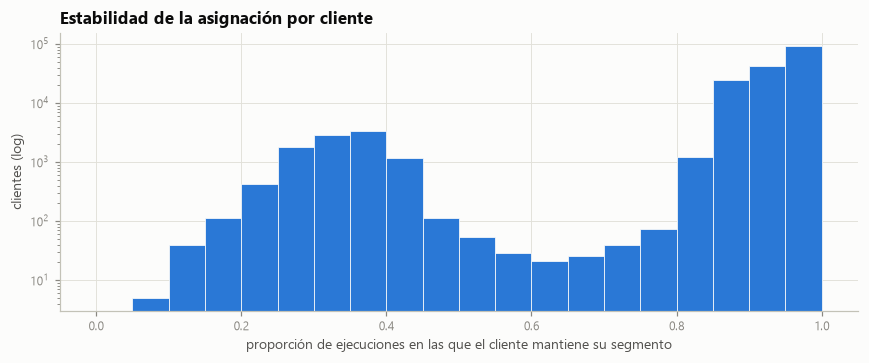

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 1, 21)
ax.hist(multi.coincidencia, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set_yscale("log")
ax.set_xlabel("proporción de ejecuciones en las que el cliente mantiene su segmento")
ax.set_ylabel("clientes (log)")
ax.set_title("Estabilidad de la asignación por cliente")
save(fig, "a3_estabilidad_clientes.png")

## 3. Análisis por clúster

In [7]:
jac_cols = [f"Jaccard {c}" for c in range(K)]
por_cl = pd.DataFrame({
    "segmento": [NOMBRES.get(c, c) for c in range(K)],
    "clientes": np.bincount(ref, minlength=K),
    "Jaccard medio": runs[jac_cols].mean().to_numpy(),
    "Jaccard mínimo": runs[jac_cols].min().to_numpy(),
    "% coincidencia medio": multi.groupby("cluster").coincidencia.mean().reindex(range(K)).to_numpy() * 100,
    "% clientes que saltan": multi.groupby("cluster").coincidencia.apply(lambda s: (s < 1).mean() * 100).reindex(range(K)).to_numpy(),
}, index=pd.Index(range(K), name="cluster"))
por_cl["estabilidad"] = pd.cut(por_cl["Jaccard medio"], [0, .6, .75, .85, 1.01],
                               labels=["inestable", "patrón débil", "estable", "muy estable"])
por_cl.sort_values("Jaccard medio").to_csv(PROC / "estabilidad_jackknife.csv")
por_cl.sort_values("Jaccard medio")

,segmento,clientes,Jaccard medio,Jaccard mínimo,% coincidencia medio,% clientes que saltan,estabilidad
cluster,,,,,,,
3,Urbano en leasing,21621,0.760,0.345,94.912,17.053,estable
1,Compacto clásico al contado,57201,0.836,0.415,84.696,89.775,estable
5,Entusiasta AMG,17624,0.896,0.101,92.682,79.295,muy estable
4,Familia SUV híbrida,35576,0.942,0.634,96.762,26.456,muy estable
2,Profesional de furgoneta,16163,0.979,0.949,99.680,2.363,muy estable
6,Élite eléctrica y lujo,7288,0.980,0.942,99.676,2.264,muy estable
0,Ex-cliente por recuperar,17150,1.000,1.000,100.000,0.000,muy estable


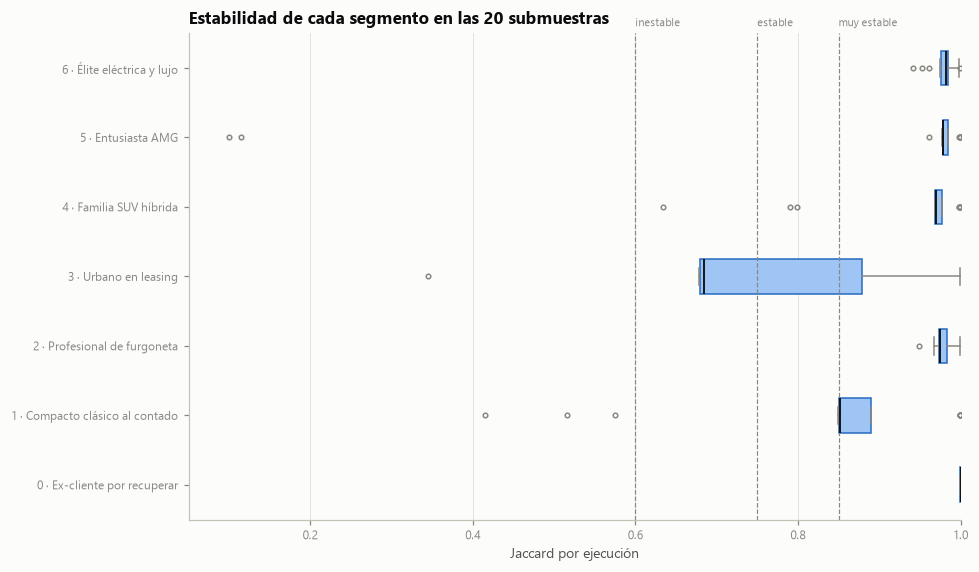

In [8]:
fig, ax = plt.subplots(figsize=(9, 0.5 * K + 1.8))
data = [runs[f"Jaccard {c}"].to_numpy() for c in range(K)]
bp = ax.boxplot(data, orientation="horizontal", widths=0.5, patch_artist=True,
                medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                flierprops=dict(markersize=3, markeredgecolor=MUTED))
for b in bp["boxes"]:
    b.set(facecolor="#9ec5f4", edgecolor="#256abf")
ax.set_yticks(range(1, K + 1)); ax.set_yticklabels([f"{c} · {NOMBRES.get(c, c)}" for c in range(K)], fontsize=8)
for x, lab in [(0.6, "inestable"), (0.75, "estable"), (0.85, "muy estable")]:
    ax.axvline(x, color=MUTED, lw=0.8, ls="--")
    ax.text(x, K + 0.6, lab, fontsize=7, color=MUTED, ha="left")
ax.set_xlim(min(0.5, min(map(min, data)) - 0.05), 1.0)
ax.set_xlabel("Jaccard por ejecución"); ax.grid(axis="y", visible=False)
ax.set_title("Estabilidad de cada segmento en las 20 submuestras")
save(fig, "a3_jaccard_por_cluster.png")

## 4. ¿Entre qué segmentos saltan los clientes?

Matriz de transiciones: para cada segmento de referencia (filas), a qué segmento se asigna a sus clientes en las
ejecuciones donde cambian (% sobre el total de cambios de esa fila).

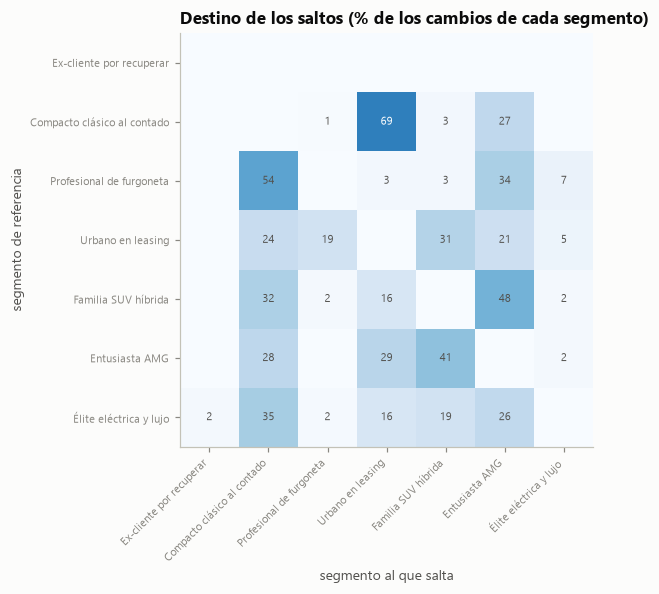

,% de todos los saltos
Compacto clásico al contado → Urbano en leasing,49.178
Compacto clásico al contado → Entusiasta AMG,19.054
Familia SUV híbrida → Entusiasta AMG,4.443
Entusiasta AMG → Familia SUV híbrida,4.304
Entusiasta AMG → Urbano en leasing,3.024


In [9]:
salto = presente & (asign != ref[None, :])
cambios = pd.DataFrame({"desde": ref[np.nonzero(salto)[1]], "hacia": asign[salto]})
if len(cambios):
    trans = pd.crosstab(cambios.desde, cambios.hacia).reindex(index=range(K), columns=range(K), fill_value=0)
    trans_pct = trans.div(trans.sum(axis=1).replace(0, np.nan), axis=0) * 100
    fig, ax = plt.subplots(figsize=(7, 5.5))
    ax.imshow(trans_pct.fillna(0).values, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xticklabels([NOMBRES.get(c, c) for c in range(K)], rotation=45, ha="right", fontsize=7.5)
    ax.set_yticklabels([NOMBRES.get(c, c) for c in range(K)], fontsize=7.5)
    ax.set_xlabel("segmento al que salta"); ax.set_ylabel("segmento de referencia"); ax.grid(False)
    for i in range(K):
        for j in range(K):
            v = trans_pct.fillna(0).values[i, j]
            if v > 0.5:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 55 else INK2)
    ax.set_title("Destino de los saltos (% de los cambios de cada segmento)")
    save(fig, "a3_transiciones.png")
    top_pairs = (trans.stack().sort_values(ascending=False).head(5) / trans.values.sum() * 100).rename("% de todos los saltos")
    top_pairs.index = [f"{NOMBRES.get(a, a)} → {NOMBRES.get(b, b)}" for a, b in top_pairs.index]
    display(top_pairs.to_frame())

### ¿Quiénes son los clientes que saltan?

Se comparan las features (escaladas) de los clientes inestables (< 80 % de coincidencia) con las de los estables.
Un cliente inestable suele estar en la frontera entre dos centroides.

In [10]:
dist_cent = np.sqrt(((Xv[:, None, :] - cent_ref[None, :, :]) ** 2).sum(-1))
orden = np.sort(dist_cent, axis=1)
cli["margen_frontera"] = orden[:, 1] - orden[:, 0]  # distancia al 2.º centroide menos distancia al propio
inest = cli.coincidencia < 0.8
comp = pd.DataFrame({
    "estables": cli.loc[~inest, "margen_frontera"].describe()[["mean", "50%"]],
    "inestables": cli.loc[inest, "margen_frontera"].describe()[["mean", "50%"]]}).T
comp.columns = ["margen medio", "margen mediano"]
display(comp)
diff = (X[inest.to_numpy()].mean() - X[~inest.to_numpy()].mean()).sort_values(key=abs, ascending=False).head(6)
diff.rename("diferencia de medias (inestables − estables, en desviaciones estándar)").to_frame()

,margen medio,margen mediano
estables,1.251,1.139
inestables,0.379,0.388


,"diferencia de medias (inestables − estables, en desviaciones estándar)"
share_electrificado,1.482
share_compacto,0.765
share_suv,-0.516
edad_vehiculo,-0.480
n_vehiculos_actuales,0.468
tiene_vehiculo_actual,0.361


In [11]:
mas = por_cl["Jaccard medio"].idxmax(); menos = por_cl["Jaccard medio"].idxmin()
global_ok = runs.ARI.mean() >= 0.8 and por_cl["Jaccard medio"].min() >= 0.75
show_md(f"""## 5. Conclusiones y recomendación

- **Estabilidad global:** ARI medio = **{runs.ARI.mean():.3f}** (mín. {runs.ARI.min():.3f}) y coincidencia media por cliente =
  **{multi.coincidencia.mean() * 100:.1f} %**. El {(multi.coincidencia == 1).mean() * 100:.1f} % de los clientes conserva su segmento en todas las submuestras.
- **Segmento más estable:** {NOMBRES.get(mas, mas)} (Jaccard {por_cl.loc[mas, 'Jaccard medio']:.3f}).
- **Segmento menos estable:** {NOMBRES.get(menos, menos)} (Jaccard {por_cl.loc[menos, 'Jaccard medio']:.3f}, {por_cl.loc[menos, 'estabilidad']}).
- **Ejecuciones atípicas:** {(runs.ARI < 0.8).sum()} de {N_RUNS} submuestras tienen un ARI < 0,8 (mín. {runs.ARI.min():.2f}). En ellas K-Means
  converge a una partición alternativa que redistribuye las fronteras entre {NOMBRES[1]}, {NOMBRES[3]} y {NOMBRES[5]}
  (de ahí sus Jaccard mínimos bajos), mientras que el resto de segmentos no cambia.
- **Quién salta:** los clientes inestables tienen un margen a la frontera mucho menor
  ({comp.loc['inestables', 'margen mediano']:.2f} frente a {comp.loc['estables', 'margen mediano']:.2f} de mediana): son perfiles intermedios
  entre dos segmentos vecinos, no errores del modelo.

**Recomendación:** {"la segmentación es **robusta en conjunto** y se puede usar para decisiones de marketing." if global_ok else
"la segmentación es **utilizable con cautela**: los segmentos menos estables deberían revisarse o fusionarse antes de lanzar campañas específicas sobre ellos."}
Cuatro segmentos (Ex-cliente, Furgoneta, Élite eléctrica y Familia SUV) son muy estables y pueden activarse ya. En
{NOMBRES[1]}, {NOMBRES[3]} y {NOMBRES[5]} conviene usar el margen a la frontera y fijar el modelo de referencia (semilla y
`n_init` altos) para que las asignaciones no cambien de una campaña a otra.
Para las campañas conviene usar el `margen_frontera` como medida de confianza: a los clientes con margen bajo se les puede
aplicar la estrategia de los dos segmentos vecinos, o dejarlos para comunicaciones genéricas. El modelo debería reentrenarse
y volver a pasar este test periódicamente, por ejemplo cada trimestre.""")

## 5. Conclusiones y recomendación

- **Estabilidad global:** ARI medio = **0.852** (mín. 0.569) y coincidencia media por cliente =
  **92.8 %**. El 54.3 % de los clientes conserva su segmento en todas las submuestras.
- **Segmento más estable:** Ex-cliente por recuperar (Jaccard 1.000).
- **Segmento menos estable:** Urbano en leasing (Jaccard 0.760, estable).
- **Ejecuciones atípicas:** 3 de 20 submuestras tienen un ARI < 0,8 (mín. 0.57). En ellas K-Means
  converge a una partición alternativa que redistribuye las fronteras entre Compacto clásico al contado, Urbano en leasing y Entusiasta AMG
  (de ahí sus Jaccard mínimos bajos), mientras que el resto de segmentos no cambia.
- **Quién salta:** los clientes inestables tienen un margen a la frontera mucho menor
  (0.39 frente a 1.14 de mediana): son perfiles intermedios
  entre dos segmentos vecinos, no errores del modelo.

**Recomendación:** la segmentación es **robusta en conjunto** y se puede usar para decisiones de marketing.
Cuatro segmentos (Ex-cliente, Furgoneta, Élite eléctrica y Familia SUV) son muy estables y pueden activarse ya. En
Compacto clásico al contado, Urbano en leasing y Entusiasta AMG conviene usar el margen a la frontera y fijar el modelo de referencia (semilla y
`n_init` altos) para que las asignaciones no cambien de una campaña a otra.
Para las campañas conviene usar el `margen_frontera` como medida de confianza: a los clientes con margen bajo se les puede
aplicar la estrategia de los dos segmentos vecinos, o dejarlos para comunicaciones genéricas. El modelo debería reentrenarse
y volver a pasar este test periódicamente, por ejemplo cada trimestre.